In [1]:
import pandas as pd
df = pd.read_csv("employee_data_raw.csv")
print(df.shape)
df.head()

(63, 7)


,Employee ID,Name,Age,City,Department,Salary,Join Date
0,1001,Anjali Rao,25.0,delhi,HR,34000,2024-09-04
1,1002,Anjali Rao,54.0,pune,Sales,52000,2018-02-14
2,1003,Karan Verma,27.0,MUMBAI,Marketing,95000,2021/01/27
3,1004,Pooja Joshi,25.0,Mumbai,Marketing,98000,2022-07-02
4,1005,Sneha Iyer,30.0,Mumbai,Finance,62000,2021-03-18


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Employee ID  63 non-null     int64  
 1   Name         63 non-null     object 
 2   Age          57 non-null     float64
 3   City         60 non-null     object 
 4   Department   63 non-null     object 
 5   Salary       62 non-null     object 
 6   Join Date    63 non-null     object 
dtypes: float64(1), int64(1), object(5)
memory usage: 3.6+ KB


In [3]:
# Tidy column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Remove duplicates
df = df.drop_duplicates()

# Fix text (spaces + capitalization)
df["city"] = df["city"].str.strip().str.title()
df["department"] = df["department"].str.strip().str.title()

# Fix data types
df["salary"] = df["salary"].astype(str).str.replace("$", "", regex=False)
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")
df["join_date"] = df["join_date"].str.replace("/", "-")
df["join_date"] = pd.to_datetime(df["join_date"])

# Handle missing values
df["age"] = df["age"].fillna(df["age"].median())
df["salary"] = df["salary"].fillna(df["salary"].median())
df["city"] = df["city"].fillna("Unknown")

In [4]:
df.isnull().sum()
df.duplicated().sum()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60 entries, 0 to 59
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   employee_id  60 non-null     int64         
 1   name         60 non-null     object        
 2   age          60 non-null     float64       
 3   city         60 non-null     object        
 4   department   60 non-null     object        
 5   salary       60 non-null     float64       
 6   join_date    60 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 3.8+ KB


In [5]:
df.to_csv("employee_data_cleaned.csv", index=False)

In [7]:
df.duplicated().sum()

0

In [10]:
df.isnull().sum()

employee_id    0
name           0
age            0
city           0
department     0
salary         0
join_date      0
dtype: int64

In [12]:

!pip install matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Task1_data_cleaning.csv", parse_dates=["join_date"])
df.head()

,employee_id,name,age,city,department,salary,join_date
0,1001,Anjali Rao,25.0,Delhi,Hr,34000.0,2024-09-04
1,1002,Anjali Rao,54.0,Pune,Sales,52000.0,2018-02-14
2,1003,Karan Verma,27.0,Mumbai,Marketing,95000.0,2021-01-27
3,1004,Pooja Joshi,25.0,Mumbai,Marketing,98000.0,2022-07-02
4,1005,Sneha Iyer,30.0,Mumbai,Finance,62000.0,2021-03-18


In [15]:
df.describe()

,employee_id,age,salary,join_date
count,60.000000,60.000000,60.000000,60
mean,1030.500000,38.550000,74983.333333,2021-06-15 10:00:00
min,1001.000000,22.000000,25000.000000,2018-02-14 00:00:00
25%,1015.750000,30.000000,52000.000000,2019-10-23 18:00:00
50%,1030.500000,38.500000,78000.000000,2021-06-23 00:00:00
75%,1045.250000,47.000000,97250.000000,2023-02-18 18:00:00
max,1060.000000,55.000000,119000.000000,2024-12-06 00:00:00
std,17.464249,10.350919,26353.844904,NaN


In [17]:
df.describe(include="object")

,name,city,department
count,60,60,60
unique,15,7,5
top,Anjali Rao,Delhi,Sales
freq,8,14,13


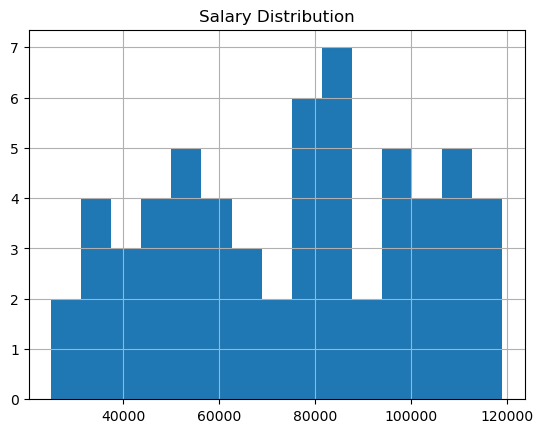

In [18]:
df["salary"].hist(bins=15)
plt.title("Salary Distribution")
plt.show()

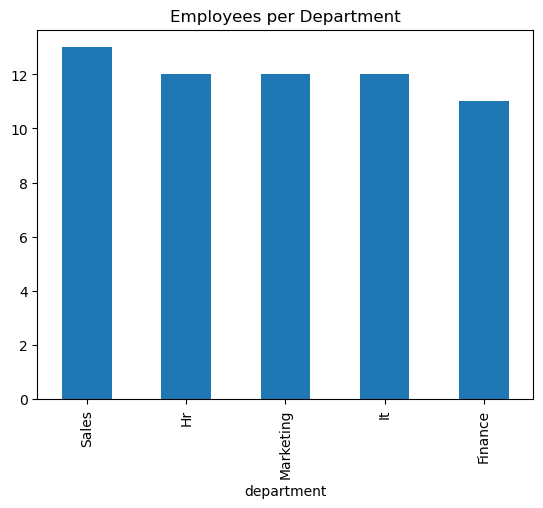

In [19]:
df["department"].value_counts().plot(kind="bar", title="Employees per Department")
plt.show()

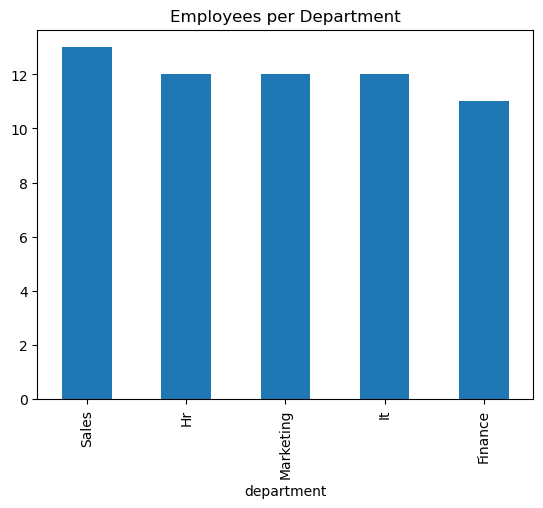

In [20]:
df["department"].value_counts().plot(kind="bar", title="Employees per Department")
plt.show()

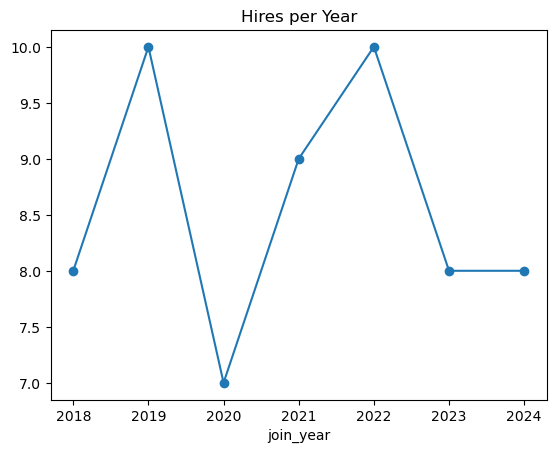

In [21]:
df["join_year"] = df["join_date"].dt.year
df.groupby("join_year")["employee_id"].count().plot(kind="line", marker="o", title="Hires per Year")
plt.show()

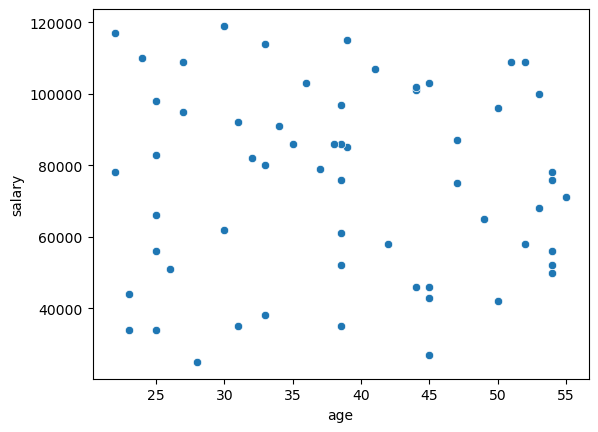

,age,salary
age,1.000000,-0.024912
salary,-0.024912,1.000000


In [22]:
sns.scatterplot(data=df, x="age", y="salary")
plt.show()
df[["age", "salary"]].corr()

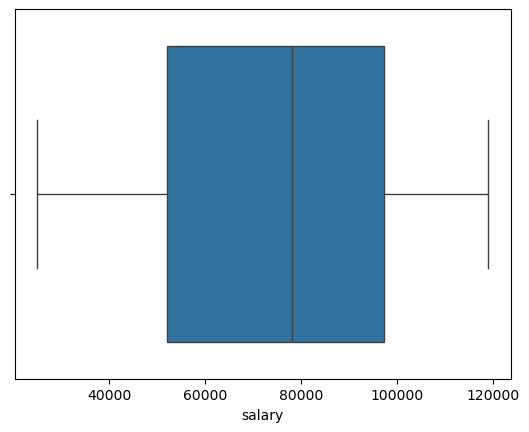

In [23]:
sns.boxplot(x=df["salary"])
plt.show()

In [24]:
Q1 = df["salary"].quantile(0.25)
Q3 = df["salary"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df["salary"] < Q1 - 1.5*IQR) | (df["salary"] > Q3 + 1.5*IQR)]
outliers

,employee_id,name,age,city,department,salary,join_date,join_year


In [25]:
df.groupby("city")["salary"].mean().sort_values(ascending=False)   # Which city pays most?
df.groupby("department")["salary"].median()                        # Which dept pays most?
df["department"].value_counts().idxmax()                          # Largest department?

'Sales'

In [26]:
print(df.groupby("city")["salary"].mean().sort_values(ascending=False))
print(df.groupby("department")["salary"].median())
print(df["department"].value_counts())

city
Unknown      92500.000000
Delhi        86785.714286
Chennai      75444.444444
Mumbai       74000.000000
Hyderabad    73500.000000
Bangalore    70750.000000
Pune         59900.000000
Name: salary, dtype: float64
department
Finance      68000.0
Hr           76000.0
It           93500.0
Marketing    64500.0
Sales        79000.0
Name: salary, dtype: float64
department
Sales        13
Hr           12
Marketing    12
It           12
Finance      11
Name: count, dtype: int64


**##Key Findings**
 
1.The dataset has 60 employees across 5 departments. Sales is the largest with 13 employees, and the others are close (HR,     Marketing and IT have 12 each, Finance has 11).

2.Average salary is 74,983 and median salary is 78,000. Salaries range from 25,000 to 119,000.

3.Delhi has the highest average salary (about 86,786), and IT has the highest median salary (93,500). Pune pays the least on   average (about 59,900). Rows with a missing city were labelled "Unknown" and are left out of this comparison.

4.Age and salary show no correlation (value = -0.02).

5.No salary outliers were found using the IQR method.

6.Hiring peaked in 2019 and 2022 (10 hires each). The other years had 7 to 9 hires per year.

**Conclusion:**
Salary appears driven more by department and city than by age. IT pays the most and Marketing and Finance the least, while salary does not rise with age. Further analysis could include experience or job role, and a larger dataset would make the differences more reliable.